# **Project Name**    - Hotel Recommendation System (Travel MLOps Capstone)

##### **Project Type**    - Recommender System (Unsupervised / Collaborative Filtering)
##### **Contribution**    - Individual
##### **Team Member 1 -** Anson Sibi

# **Project Summary -**

Suggesting the right hotel at the right time increases bookings and customer satisfaction. In this notebook I built a **hotel recommendation model** that ranks the hotels a user is most likely to book next, based on their own booking history and on users with similar habits. It has a cold-start mode for new users and is served through a **Streamlit web app** that also shows travel insights.

**Data.** `hotels.csv` has 40,552 hotel stays by 1,310 users across 9 hotels, one per city (Hotel A in Florianópolis, Hotel K in Salvador and so on), each with a fixed nightly price between R$60 and R$313. Stays last 1–4 nights. `users.csv` adds company, age and gender, and `flights.csv` shows that about 30% of trips include a hotel stay at the destination.

**EDA and hypothesis findings.**
* Users are very active (median 30 stays) and most visit 7–9 of the 9 hotels. about 76% of stays are at a hotel the user already knows, but the next stay is the same hotel as the previous one only 11.5% of the time, so users rotate among familiar hotels.
* Hotel choice **depends strongly on the company** (χ² ≈ 3,147, p ≈ 0): some companies never use certain hotels, probably because of corporate travel contracts. It is **independent of gender** (p ≈ 0.63).
* Total hotel spend differs by company (Kruskal–Wallis p ≈ 10⁻⁶⁰).

**Approach.** I framed the task as *next-hotel prediction* and evaluated it with a **time-based leave-last-out split**: each user's last stay is the test target, the second-last is used for tuning, and everything before is training data. I compared:
1. a **popularity** baseline (and random guessing),
2. **user-based collaborative filtering** (cosine similarity between users' booking vectors, k nearest neighbours),
3. a **hybrid** model that blends the user's own preference profile, the neighbours' preferences and popularity, with weights tuned on the validation stays.

Metrics are **HitRate@3** (is the next hotel in the top 3?) and **NDCG@3** (is it near the top?). All personalised models reach **HitRate@3 ≈ 0.38**, against 0.32 for random guessing and 0.35 for popularity, about 13% above the expected random hit rate of 3/9 = 0.33. I selected the hybrid configuration chosen on the validation stays. The differences between personalised variants are within sampling noise, and the ceiling is low because users pick almost at random among the hotels they know. I explain this in the analysis.

**Deployment.** The production version (`src/travel_ml/recommender.py`) is retrained by the Airflow DAG, served by the Flask API (`GET /recommend/<user>`, `POST /recommend/profile`) and used by the **Streamlit app**. In the app a user picks a customer (or enters age + company for a new one), sets a budget per night, can choose to explore new cities, and sees ranked hotels, their booking history and dashboards of travel trends.

# **GitHub Link -**

https://github.com/ansonsibi/travel-mlops-capstone

# **Problem Statement**

**Build a recommendation model that suggests hotels to users based on their preferences and historical bookings**, and expose it through an interactive Streamlit web app that also shows insights and visualisations from the travel data.

# **General Guidelines** : -

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

     The additional credits will have advantages over other students during Star Student selection.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.

```
# Chart visualization code
```

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]

6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.

*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.

*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
K = 3          # we recommend the top-3 hotels

### Dataset Loading

In [2]:
# The notebook works both locally (repo checkout) and on Google Colab.
# Locally it reads ../data/raw/, on Colab it downloads the same CSVs from the GitHub repo.
GITHUB_RAW = "https://raw.githubusercontent.com/ansonsibi/travel-mlops-capstone/main/data/raw/"
LOCAL_DIR = "../data/raw/"


def read_dataset(file_name: str) -> pd.DataFrame:
    """Read a CSV from the local repo if present, otherwise from GitHub."""
    local_path = os.path.join(LOCAL_DIR, file_name)
    source = local_path if os.path.exists(local_path) else GITHUB_RAW + file_name
    try:
        return pd.read_csv(source)
    except Exception as exc:  # network issues / wrong path
        raise RuntimeError(f"Could not load {file_name} from {source}: {exc}")


# Load Dataset
hotels = read_dataset("hotels.csv")
users = read_dataset("users.csv")
flights = read_dataset("flights.csv")

### Dataset First View

In [3]:
# Dataset First Look
hotels.head(10)

,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,09/26/2019
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,10/10/2019
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,11/14/2019
3,11,0,Hotel K,Salvador (BH),4,263.41,1053.64,12/12/2019
4,13,0,Hotel A,Florianopolis (SC),1,313.02,313.02,12/26/2019
5,15,0,Hotel BD,Natal (RN),2,242.88,485.76,01/09/2020
6,22,0,Hotel Z,Aracaju (SE),2,208.04,416.08,02/27/2020
7,29,0,Hotel AU,Recife (PE),4,312.83,1251.32,04/16/2020
8,32,0,Hotel AF,Sao Paulo (SP),2,139.10,278.20,05/07/2020
9,33,0,Hotel K,Salvador (BH),4,263.41,1053.64,05/14/2020


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, data in [("hotels", hotels), ("users", users), ("flights", flights)]:
    print(f"{name:<8} rows: {data.shape[0]:>7,}  columns: {data.shape[1]}")

hotels   rows:  40,552  columns: 8
users    rows:   1,340  columns: 5
flights  rows: 271,888  columns: 10


### Dataset Information

In [5]:
# Dataset Info
hotels.info()

<class 'pandas.DataFrame'>
RangeIndex: 40552 entries, 0 to 40551
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   travelCode  40552 non-null  int64  
 1   userCode    40552 non-null  int64  
 2   name        40552 non-null  str    
 3   place       40552 non-null  str    
 4   days        40552 non-null  int64  
 5   price       40552 non-null  float64
 6   total       40552 non-null  float64
 7   date        40552 non-null  str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.7 MB


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("duplicate rows:", hotels.duplicated().sum())
print("duplicate travelCodes:", hotels["travelCode"].duplicated().sum(), "(one hotel stay per trip)")

duplicate rows: 0
duplicate travelCodes: 0 (one hotel stay per trip)


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
hotels.isnull().sum()

travelCode    0
userCode      0
name          0
place         0
days          0
price         0
total         0
date          0
dtype: int64

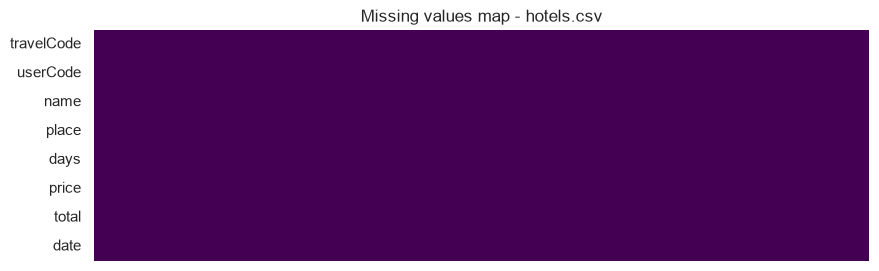

In [8]:
# Visualizing the missing values
plt.figure(figsize=(10, 3))
sns.heatmap(hotels.isnull().T, cbar=False, xticklabels=False, cmap="viridis")
plt.title("Missing values map - hotels.csv")
plt.show()

### What did you know about your dataset?

* `hotels.csv` has **40,552 stays and 8 columns**, with no missing values and no duplicates. Each `travelCode` appears once, so one trip has at most one hotel stay.
* There are only **9 hotels**, one per city, so recommending a hotel is the same as recommending a destination.
* The interactions are **implicit feedback** (bookings, no ratings), which shapes the choice of model and metrics.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(hotels.columns)

['travelCode', 'userCode', 'name', 'place', 'days', 'price', 'total', 'date']

In [10]:
# Dataset Describe
hotels.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
travelCode,40552.0,NaN,NaN,NaN,67911.794461,39408.199333,0.0,33696.75,67831.0,102211.25,135942.0
userCode,40552.0,NaN,NaN,NaN,666.963726,391.136794,0.0,323.0,658.0,1013.0,1339.0
name,40552,9,Hotel K,5094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place,40552,9,Salvador (BH),5094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days,40552.0,NaN,NaN,NaN,2.499679,1.119326,1.0,1.0,2.0,4.0,4.0
price,40552.0,NaN,NaN,NaN,214.439554,76.742305,60.39,165.99,242.88,263.41,313.02
total,40552.0,NaN,NaN,NaN,536.229513,319.331482,60.39,247.62,495.24,742.86,1252.08
date,40552,199,10/03/2019,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description 

| Variable | Type | Description |
|---|---|---|
| `travelCode` | int (ID) | Trip identifier (same code as in flights.csv). |
| `userCode` | int (ID) | User who booked (links to `users.code`). |
| `name` | categorical | Hotel name (9 hotels), **the item we recommend**. |
| `place` | categorical | City of the hotel (one hotel per city). |
| `days` | int | Number of nights (1–4). |
| `price` | float | Price per night (fixed per hotel). |
| `total` | float | `days × price`. |
| `date` | date | Check-in date (2019-09 to 2023-07). |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in hotels.columns:
    print(f"{col:<11} {hotels[col].nunique():>6} unique values")
print()
print(hotels.groupby(["name", "place"])["price"].agg(["min", "max"]))

travelCode   40552 unique values
userCode      1310 unique values
name             9 unique values
place            9 unique values
days             4 unique values
price            9 unique values
total           36 unique values
date           199 unique values

                                 min     max
name     place                              
Hotel A  Florianopolis (SC)   313.02  313.02
Hotel AF Sao Paulo (SP)       139.10  139.10
Hotel AU Recife (PE)          312.83  312.83
Hotel BD Natal (RN)           242.88  242.88
Hotel BP Brasilia (DF)        247.62  247.62
Hotel BW Campo Grande (MS)     60.39   60.39
Hotel CB Rio de Janeiro (RJ)  165.99  165.99
Hotel K  Salvador (BH)        263.41  263.41
Hotel Z  Aracaju (SE)         208.04  208.04


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
hotels["date"] = pd.to_datetime(hotels["date"], format="%m/%d/%Y")
hotels["month"] = hotels["date"].dt.to_period("M").dt.to_timestamp()
check = (hotels["days"] * hotels["price"] - hotels["total"]).abs().max()
print("max |days*price - total|:", round(check, 4))

# enrich stays with user profile
stays = hotels.merge(users.rename(columns={"name": "user_name"}), left_on="userCode", right_on="code", how="left")
stays["age_band"] = pd.cut(stays["age"], bins=[20, 30, 40, 50, 65], labels=["21-30", "31-40", "41-50", "51-65"])

# hotel catalogue (item features)
catalog = hotels.groupby("name").agg(place=("place", "first"), price_per_night=("price", "first"),
                                     stays=("travelCode", "count"), guests=("userCode", "nunique"),
                                     avg_nights=("days", "mean")).sort_values("stays", ascending=False)

# user x hotel interaction matrix (number of stays)
interactions = hotels.pivot_table(index="userCode", columns="name", values="travelCode", aggfunc="count", fill_value=0)
print("interaction matrix:", interactions.shape, "| density:", round((interactions > 0).to_numpy().mean(), 3))
catalog

max |days*price - total|: 0.0
interaction matrix: (1310, 9) | density: 0.825


,place,price_per_night,stays,guests,avg_nights
name,,,,,
Hotel K,Salvador (BH),263.41,5094,1158,2.516490
Hotel CB,Rio de Janeiro (RJ),165.99,5029,1166,2.485981
Hotel BD,Natal (RN),242.88,4829,1152,2.499068
Hotel AF,Sao Paulo (SP),139.10,4828,1151,2.511599
Hotel AU,Recife (PE),312.83,4467,1130,2.520931
Hotel BP,Brasilia (DF),247.62,4437,1120,2.486365
Hotel BW,Campo Grande (MS),60.39,4333,992,2.495500
Hotel Z,Aracaju (SE),208.04,4205,1106,2.491558
Hotel A,Florianopolis (SC),313.02,3330,749,2.483183


### What all manipulations have you done and insights you found?

**Manipulations**
* Parsed `date` and added a `month` column, and checked that `total = days × price` (it is exact).
* Joined the user profile (company, age, gender) onto every stay and created `age_band`.
* Built a **hotel catalogue** (city, price, popularity, guests) and the **user × hotel interaction matrix**, the main input of a collaborative-filtering recommender.

**Insights**
* The interaction matrix is **very dense (≈ 82% of user–hotel pairs are non-zero)**. Users have tried most hotels, which is unusual for recommenders and means the main task is to *rank* familiar options, not to discover hidden ones.
* Each hotel has one fixed nightly price, from R$60 (Hotel BW, Campo Grande) to R$313 (Hotel A, Florianópolis).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Stays per hotel (Univariate)

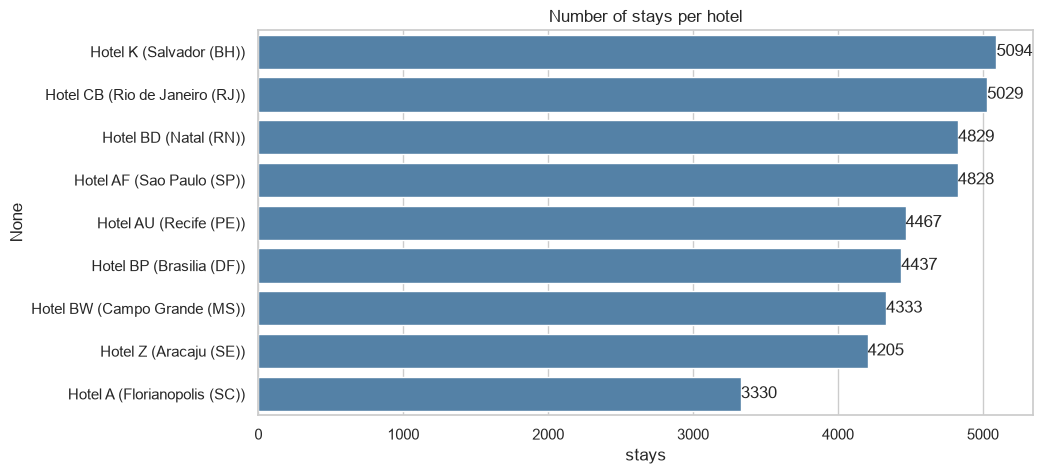

In [13]:
# Chart - 1 visualization code
ax = sns.barplot(x=catalog["stays"], y=catalog.index + " (" + catalog["place"] + ")", orient="h", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Number of stays per hotel")
plt.xlabel("stays")
plt.show()

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart ranks the items by popularity, which is the basis of the popularity baseline.

##### 2. What is/are the insight(s) found from the chart?

Popularity is fairly even. Hotel K (Salvador) is the most booked with 5,094 stays, and Hotel A (Florianópolis) the least with 3,330. The most popular hotel is only 1.5× the least popular.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. No hotel dominates, so recommending "the most popular hotel" to everyone won't work well, and personalisation is needed. Hotel A has the lowest demand and the highest price, a possible revenue risk worth a promotion.

#### Chart - 2 - Price per night by hotel (Univariate)

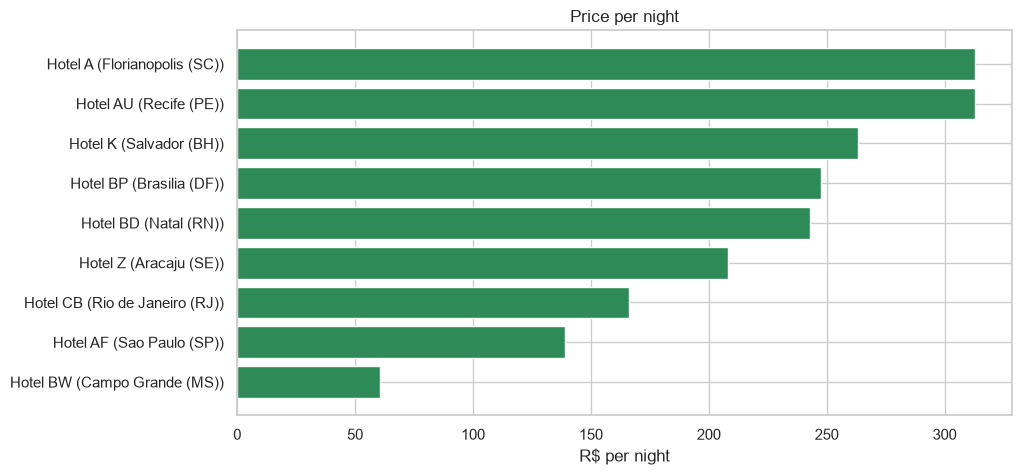

In [14]:
# Chart - 2 visualization code
cat_sorted = catalog.sort_values("price_per_night")
plt.barh(cat_sorted.index + " (" + cat_sorted["place"] + ")", cat_sorted["price_per_night"], color="seagreen")
plt.title("Price per night")
plt.xlabel("R$ per night")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares one numeric attribute (price) across the 9 hotels.

##### 2. What is/are the insight(s) found from the chart?

Prices fall into three tiers: budget (Hotel BW R$60, Hotel AF R$139, Hotel CB R$166), mid (Hotel Z R$208, Hotel BD R$243, Hotel BP R$248) and premium (Hotel K R$263, Hotel AU R$313, Hotel A R$313).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Price tiers let the app filter by **budget per night**, a key preference in the Streamlit app. Budget-conscious companies can be steered to cheaper tiers.

#### Chart - 3 - Length of stay (Univariate)

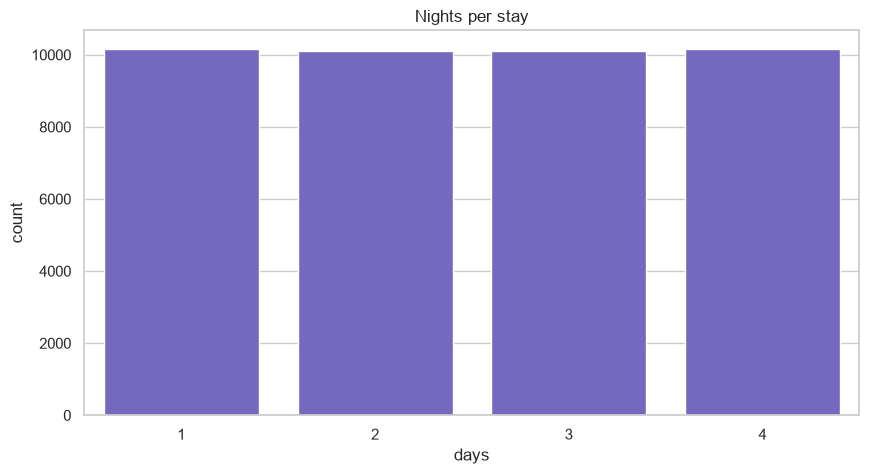

In [15]:
# Chart - 3 visualization code
sns.countplot(data=hotels, x="days", color="slateblue")
plt.title("Nights per stay")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot suits a small discrete variable.

##### 2. What is/are the insight(s) found from the chart?

Stays of 1, 2, 3 and 4 nights are equally common (~10,100 each), and nobody stays more than 4 nights. These are short business trips.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Short, predictable stays favour business-traveller packages (late check-out, breakfast included) over long-stay discounts.

#### Chart - 4 - Total spend per stay (Univariate)

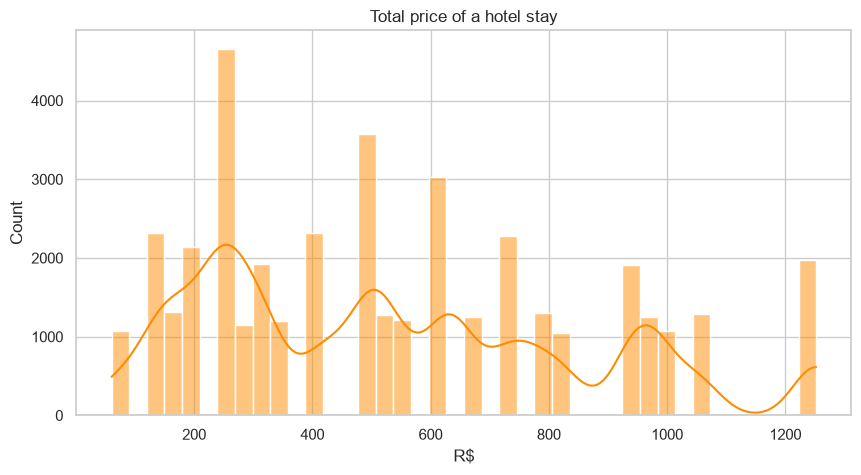

count    40552.0
mean       536.2
std        319.3
min         60.4
25%        247.6
50%        495.2
75%        742.9
max       1252.1
Name: total, dtype: float64


In [16]:
# Chart - 4 visualization code
sns.histplot(hotels["total"], bins=40, kde=True, color="darkorange")
plt.title("Total price of a hotel stay")
plt.xlabel("R$")
plt.show()
print(hotels["total"].describe().round(1))

##### 1. Why did you pick the specific chart?

A histogram with a KDE shows the distribution of booking value.

##### 2. What is/are the insight(s) found from the chart?

A stay costs R$536 on average (median R$495), ranging from R$60 to R$1,252. The distribution is lumpy because it is nightly price × 1–4 nights.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It sets realistic budget slider ranges in the app and shows the revenue per booking that each recommendation can win.

#### Chart - 5 - Stays per user (Univariate)

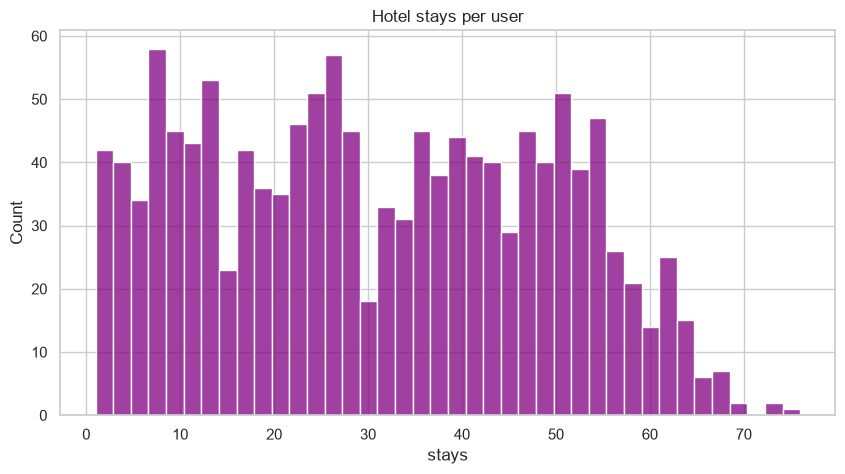

count    1310.0
mean       31.0
std        18.0
min         1.0
25%        15.0
50%        30.0
75%        46.0
max        76.0
dtype: float64


In [17]:
# Chart - 5 visualization code
per_user = hotels.groupby("userCode").size()
sns.histplot(per_user, bins=40, color="purple")
plt.title("Hotel stays per user")
plt.xlabel("stays")
plt.show()
print(per_user.describe().round(1))

##### 1. Why did you pick the specific chart?

A histogram shows how much history each user has, which matters for collaborative filtering.

##### 2. What is/are the insight(s) found from the chart?

Users have between 1 and 76 stays (median 30). Almost everyone has enough history for personalised recommendations. Only a handful of users have fewer than 3 stays.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Rich histories make personalisation possible for almost all users. The few low-history users and the 30 users with no stays at all need the cold-start mode.

#### Chart - 6 - Distinct hotels visited per user (Univariate)

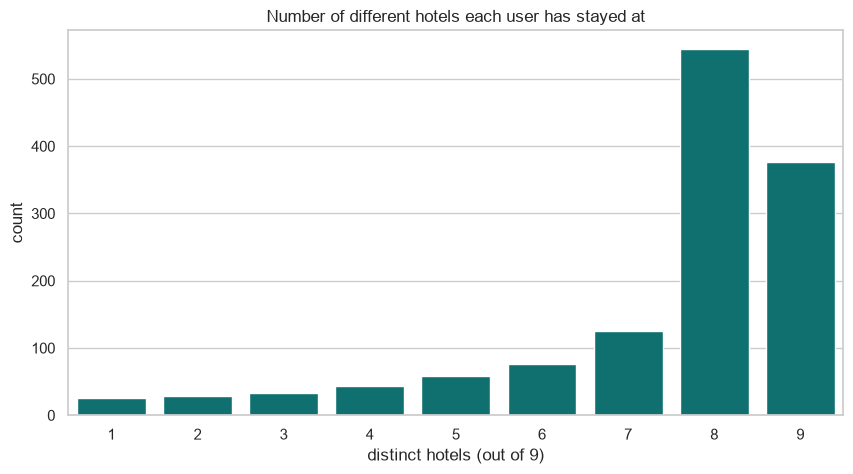

In [18]:
# Chart - 6 visualization code
distinct = (interactions > 0).sum(axis=1)
sns.countplot(x=distinct, color="teal")
plt.title("Number of different hotels each user has stayed at")
plt.xlabel("distinct hotels (out of 9)")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot of a small integer variable (0–9) shows how widely users explore the catalogue.

##### 2. What is/are the insight(s) found from the chart?

Most users have stayed at **7–9 of the 9 hotels**. They already know almost the whole catalogue.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It changes the product question from *discovering new hotels* to *ranking the right familiar one at the right time*, and it explains the "explore new places" option in the app for the users who haven't seen everything.

#### Chart - 7 - Hotel preference by company (Categorical vs categorical)

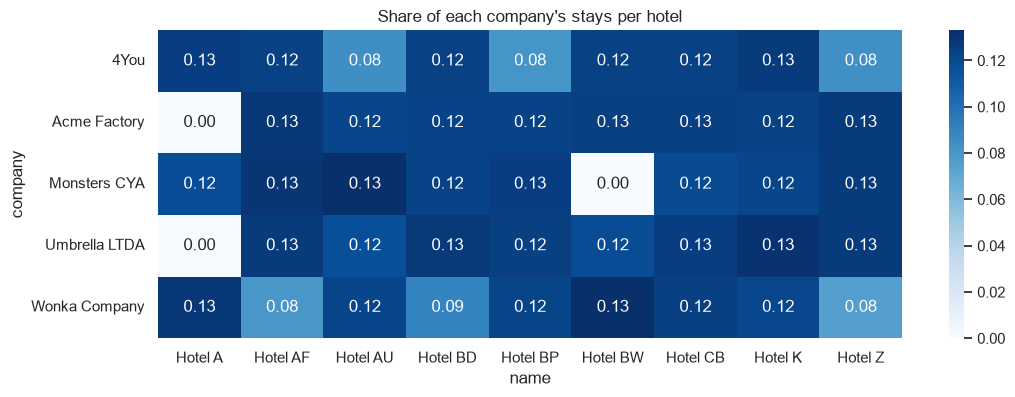

In [19]:
# Chart - 7 visualization code
company_mix = pd.crosstab(stays["company"], stays["name"], normalize="index")
plt.figure(figsize=(12, 4))
sns.heatmap(company_mix, annot=True, fmt=".2f", cmap="Blues")
plt.title("Share of each company's stays per hotel")
plt.show()

##### 1. Why did you pick the specific chart?

A row-normalised heatmap compares the hotel mix of each company regardless of company size.

##### 2. What is/are the insight(s) found from the chart?

Some companies **never** book certain hotels: e.g. Acme Factory and Umbrella LTDA have 0% at Hotel A (Florianópolis). Otherwise each company spreads its stays fairly evenly over the hotels it does use.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this is the most actionable insight: it looks like **corporate travel agreements**. Recommendations must respect them, since suggesting a hotel a company never approves would be ignored. The gaps are also sales opportunities for negotiating new contracts.

#### Chart - 8 - Hotel preference by age band (Categorical vs categorical)

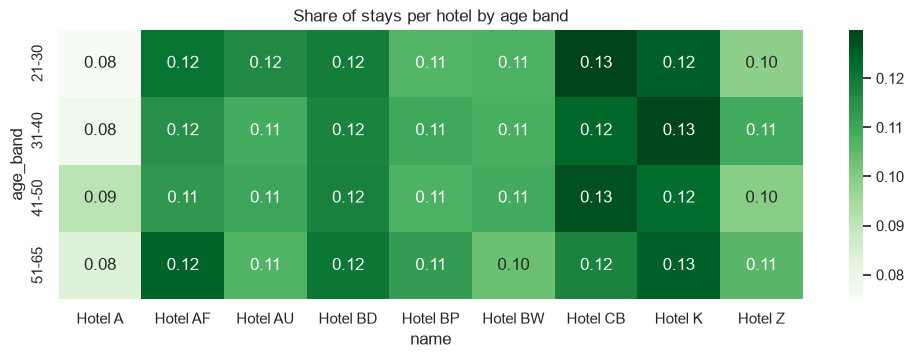

In [20]:
# Chart - 8 visualization code
age_mix = pd.crosstab(stays["age_band"], stays["name"], normalize="index")
plt.figure(figsize=(12, 3.5))
sns.heatmap(age_mix, annot=True, fmt=".2f", cmap="Greens")
plt.title("Share of stays per hotel by age band")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of a normalised crosstab compares preferences across age groups.

##### 2. What is/are the insight(s) found from the chart?

The hotel mix is very similar across age bands, with no hotel dominating any age group. Age has only a weak effect on hotel choice.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Age-specific campaigns aren't worth it for hotel choice. The cold-start recommender uses age only as a soft similarity signal, with company as the main one.

#### Chart - 9 - Hotel stays over time (Time series)

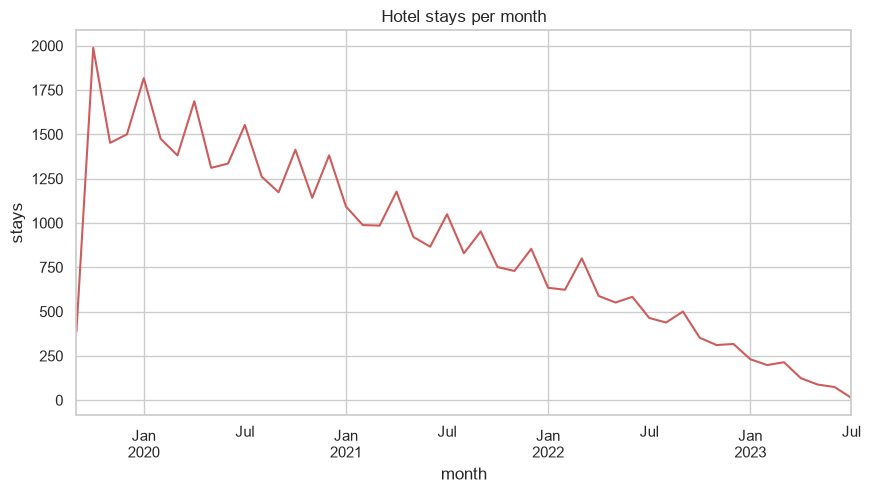

In [21]:
# Chart - 9 visualization code
monthly = hotels.groupby("month").size()
monthly.plot(color="indianred")
plt.title("Hotel stays per month")
plt.ylabel("stays")
plt.show()

##### 1. Why did you pick the specific chart?

A line chart shows the trend of bookings over time.

##### 2. What is/are the insight(s) found from the chart?

Stays peak in late 2019 and decline steadily to mid-2023, the same pattern as the flights data.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is a negative-growth signal: if real, falling bookings need retention action. Good recommendations and personalised offers are one lever to slow the decline. For evaluation it confirms that a **time-based split** (predict the latest stay) is the realistic set-up.

#### Chart - 10 - Popularity vs price (Numeric vs numeric)

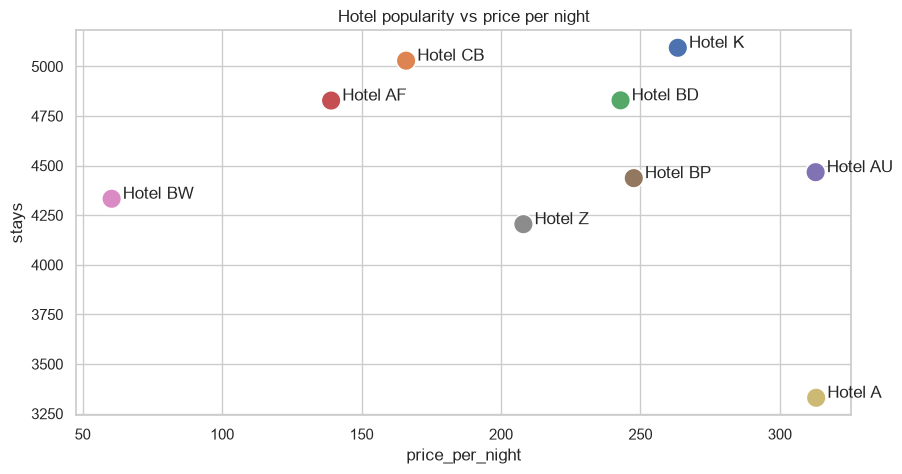

Spearman correlation: -0.12


In [22]:
# Chart - 10 visualization code
sns.scatterplot(data=catalog, x="price_per_night", y="stays", s=200, hue="place", legend=False)
for name, row in catalog.iterrows():
    plt.annotate(f"{name}", (row["price_per_night"] + 4, row["stays"]))
plt.title("Hotel popularity vs price per night")
plt.show()
print("Spearman correlation:", round(stats.spearmanr(catalog["price_per_night"], catalog["stays"])[0], 2))

##### 1. Why did you pick the specific chart?

A scatter plot of two item attributes checks whether price drives popularity.

##### 2. What is/are the insight(s) found from the chart?

There is no clear price–popularity relationship: the most and least popular hotels are both expensive (Hotel K R$263 vs Hotel A R$313). Destination matters more than price.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Lowering prices alone won't necessarily raise demand. Destination-driven marketing (events, business hubs) is probably more effective.

#### Chart - 11 - How predictable is the next stay? (Sequential behaviour)

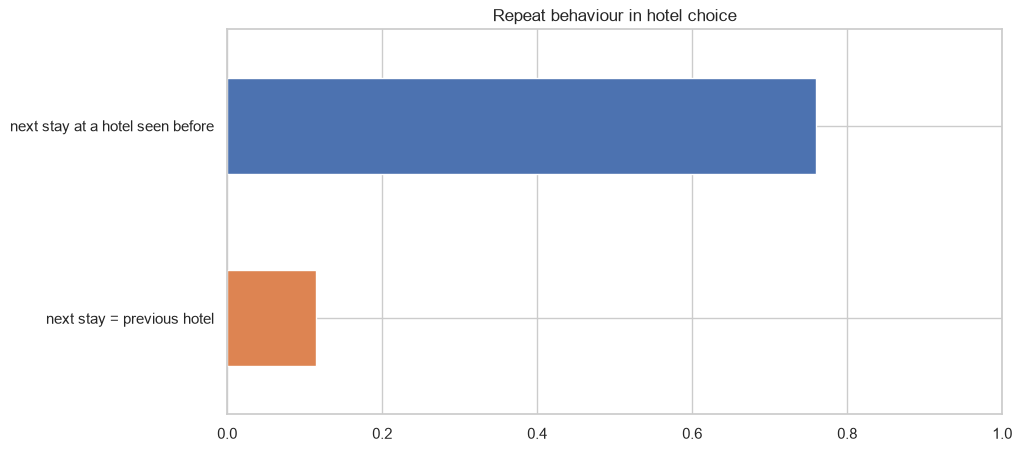

next stay = previous hotel          0.115
next stay at a hotel seen before    0.760
dtype: float64

In [23]:
# Chart - 11 visualization code
ordered = hotels.sort_values(["userCode", "date", "travelCode"])
ordered["prev_hotel"] = ordered.groupby("userCode")["name"].shift()
# was this hotel already visited by the user before this stay?
seen = []
for user, grp in ordered.groupby("userCode", sort=False):
    visited = set()
    for hotel in grp["name"]:
        seen.append(hotel in visited)
        visited.add(hotel)
ordered["seen_before"] = seen
rates = pd.Series({"next stay = previous hotel": (ordered["name"] == ordered["prev_hotel"]).mean(),
                   "next stay at a hotel seen before": ordered["seen_before"].mean()})
rates.plot(kind="barh", color=["#DD8452", "#4C72B0"], xlim=(0, 1))
plt.title("Repeat behaviour in hotel choice")
plt.show()
rates.round(3)

##### 1. Why did you pick the specific chart?

A simple bar chart of two rates summarises how repetitive users are, which tells us which recommender signals to expect to work.

##### 2. What is/are the insight(s) found from the chart?

Most stays (≈ 76%) are at a hotel the user has visited before, but the next stay is the *same* hotel as the previous one only ≈ 11% of the time (close to 1/9 random). Users rotate between hotels they know.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Recommending "your last hotel again" would fail. The value is in ranking the user's familiar set by how much they like each one, which is what the user-preference signal in the hybrid model does.

#### Chart - 12 - Hotel–hotel similarity from co-bookings (Multivariate)

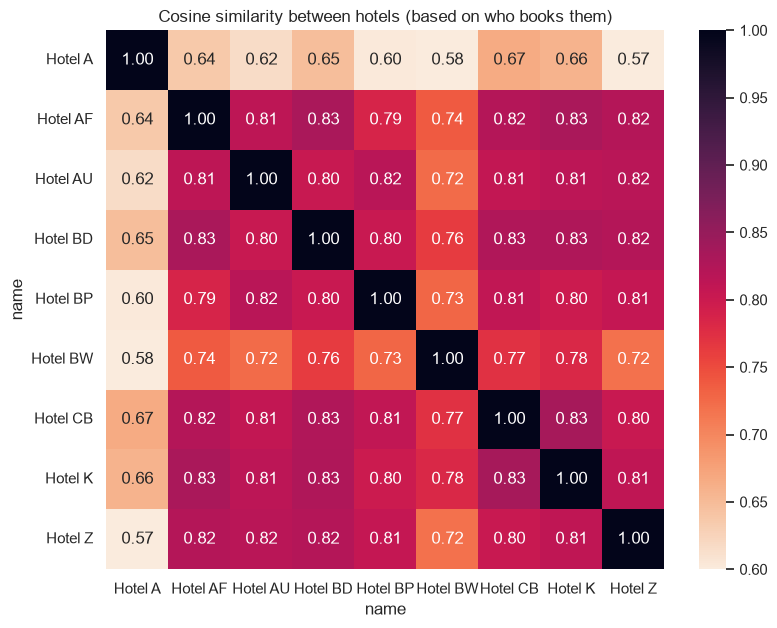

In [24]:
# Chart - 12 visualization code
item_sim = pd.DataFrame(cosine_similarity(interactions.T), index=interactions.columns, columns=interactions.columns)
plt.figure(figsize=(9, 7))
sns.heatmap(item_sim, annot=True, fmt=".2f", cmap="rocket_r", vmin=0.6, vmax=1)
plt.title("Cosine similarity between hotels (based on who books them)")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of the item–item cosine similarity matrix shows which hotels are booked by the same people, the basis of item-based collaborative filtering.

##### 2. What is/are the insight(s) found from the chart?

Hotels are all fairly similar to each other because most users visit most of them. The lower values (e.g. around Hotel A) come from the companies that never book those hotels.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The weak contrast means item-to-item recommendations ("people who stayed at X also stayed at Y") would be bland here, so I focus on user-based signals. Hotel A's distinct audience suggests a targeted campaign.

#### Chart - 13 - Do flights end in a hotel stay? (Flights ↔ hotels link)

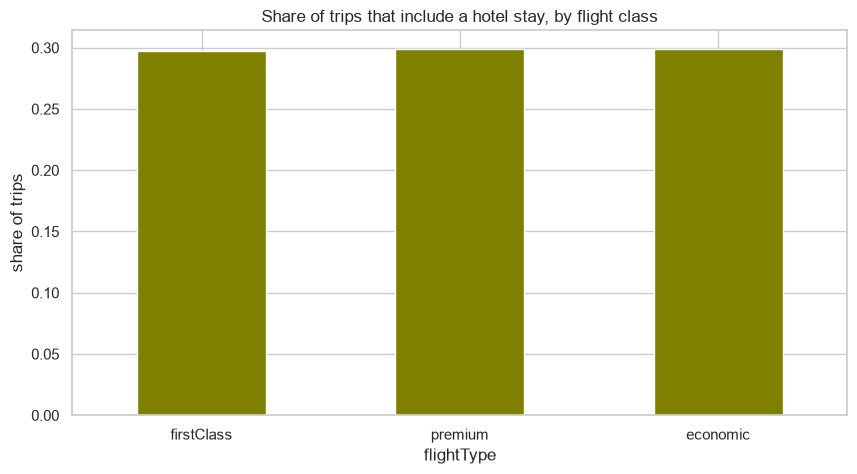

hotel city == flight destination: 1.0


In [25]:
# Chart - 13 visualization code
trip_has_hotel = flights.drop_duplicates("travelCode").assign(has_hotel=lambda d: d["travelCode"].isin(hotels["travelCode"]))
share = trip_has_hotel.groupby("flightType")["has_hotel"].mean().sort_values()
share.plot(kind="bar", rot=0, color="olive")
plt.title("Share of trips that include a hotel stay, by flight class")
plt.ylabel("share of trips")
plt.show()
# does the hotel city match the flight destination?
first_leg = flights.drop_duplicates("travelCode")[["travelCode", "to"]]
match = hotels.merge(first_leg, on="travelCode")
print("hotel city == flight destination:", round((match["place"] == match["to"]).mean(), 3))

##### 1. Why did you pick the specific chart?

A bar chart shows the cross-sell rate (flight → hotel) by class, and a join checks how the two datasets connect.

##### 2. What is/are the insight(s) found from the chart?

About 30% of trips include a hotel stay, with only small differences between flight classes, and the hotel city always matches the flight destination (100%).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, a big cross-sell opportunity: **70% of trips have no hotel booked on the platform**. When a user books a flight, the app can immediately recommend the destination's hotel (one per city), using the same pipeline.

#### Chart - 14 - Correlation Heatmap

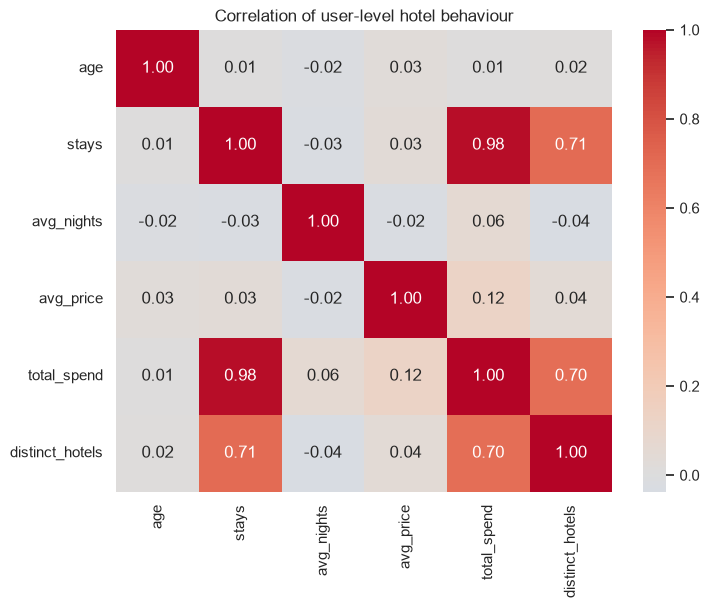

In [26]:
# Correlation Heatmap visualization code
user_level = stays.groupby("userCode").agg(age=("age", "first"), stays=("travelCode", "count"),
                                           avg_nights=("days", "mean"), avg_price=("price", "mean"),
                                           total_spend=("total", "sum"))
user_level["distinct_hotels"] = (interactions > 0).sum(axis=1)
plt.figure(figsize=(8, 6))
sns.heatmap(user_level.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of user-level hotel behaviour")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap of user-level aggregates shows how activity, spend and exploration relate.

##### 2. What is/are the insight(s) found from the chart?

Total spend is driven almost entirely by the number of stays. Users with more stays have visited more distinct hotels. Age is unrelated to every behaviour metric, and average nightly price is independent of activity.

#### Chart - 15 - Pair Plot 

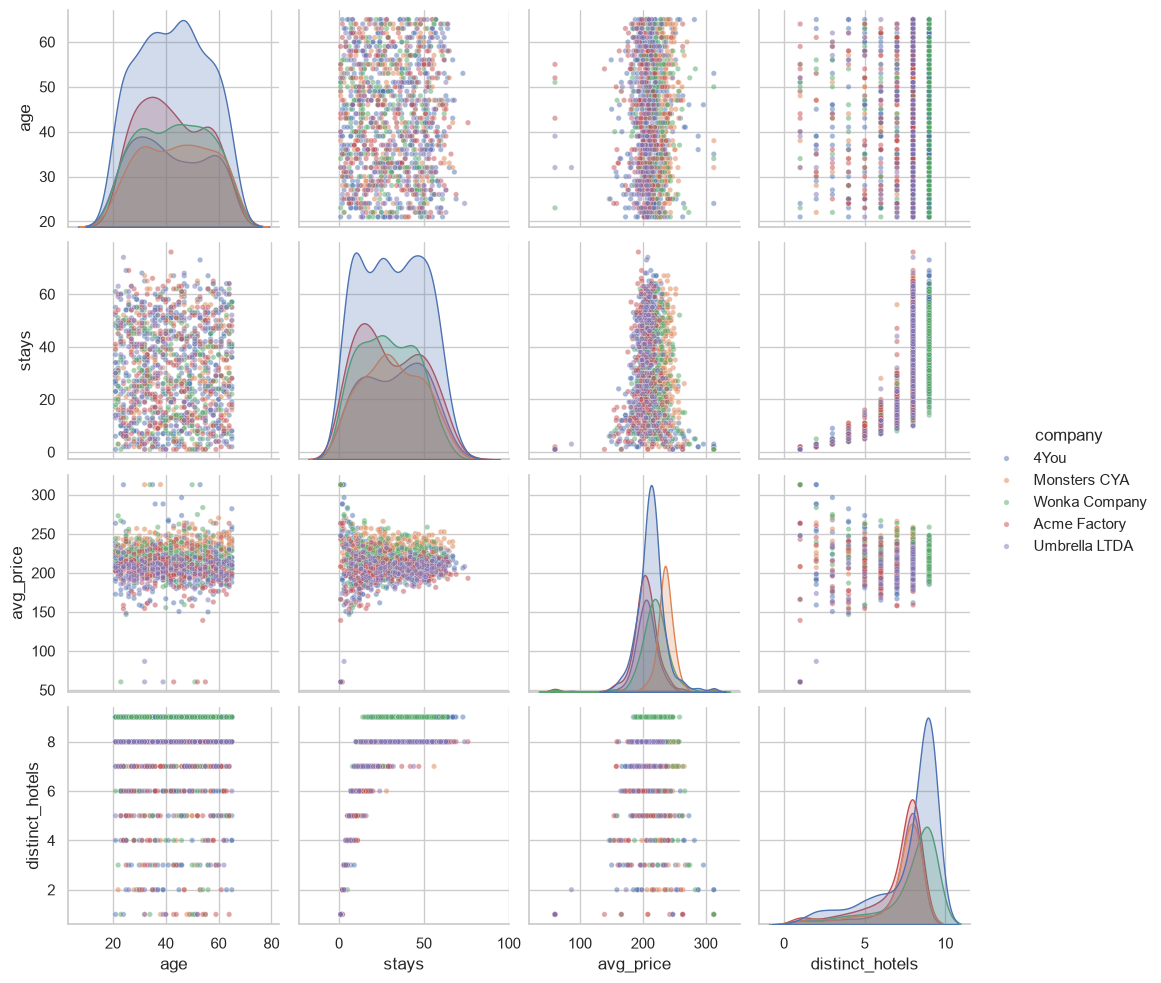

In [27]:
# Pair Plot visualization code
sns.pairplot(user_level.join(users.set_index("code")["company"]), vars=["age", "stays", "avg_price", "distinct_hotels"],
             hue="company", plot_kws={"alpha": 0.5, "s": 15})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot coloured by company checks whether companies form distinct behavioural clusters.

##### 2. What is/are the insight(s) found from the chart?

Companies overlap in age and activity, but some companies cluster at a lower `distinct_hotels` count. This is the effect of the hotels they never book (Chart 7), and it is the main company signal the recommender can exploit.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. Hotel choice depends on the user's company.
2. Hotel choice depends on the user's gender.
3. Total hotel spend per stay differs between companies.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Hotel choice is independent of company.
* **H1:** Hotel choice depends on company.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(stays["company"], stays["name"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p-value = {p_value:.2e}, Cramér's V = {cramers_v:.3f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

chi2 = 3,147, dof = 32, p-value = 0.00e+00, Cramér's V = 0.139
Reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence (with Cramér's V as effect size).

##### Why did you choose the specific statistical test?

Both variables are categorical and all expected counts are far above 5. p ≈ 0, so we **reject H0**: hotel choice depends on company. Cramér's V shows a small-to-moderate effect, mostly from the hotels some companies never book.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Hotel choice is independent of gender.
* **H1:** Hotel choice depends on gender.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(stays["gender"], stays["name"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"chi2 = {chi2:.2f}, dof = {dof}, p-value = {p_value:.3f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

chi2 = 13.58, dof = 16, p-value = 0.630
Fail to reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence.

##### Why did you choose the specific statistical test?

Same reasoning as above (two categorical variables, large counts). p ≈ 0.63, so we **fail to reject H0**: gender plays no role in hotel choice and is not used by the recommender.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** The distribution of total spend per stay is the same for every company.
* **H1:** At least one company spends differently per stay.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
groups = [g["total"].values for _, g in stays.groupby("company")]
h_stat, p_value = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:.1f}, p-value = {p_value:.2e}")
print(stays.groupby("company")["total"].mean().round(1))
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

Kruskal-Wallis H = 285.4, p-value = 1.50e-60
company
4You             534.2
Acme Factory     509.3
Monsters CYA     587.7
Umbrella LTDA    513.8
Wonka Company    546.6
Name: total, dtype: float64
Reject H0


##### Which statistical test have you done to obtain P-Value?

Kruskal–Wallis H test.

##### Why did you choose the specific statistical test?

We compare more than two independent groups, and `total` is multi-modal (price × nights), not normal, so a rank-based test is appropriate. p ≈ 10⁻⁶⁰, so we **reject H0**. Companies differ in spend per stay, which matches the different hotel mixes (budget vs premium hotels). This supports using company in the cold-start recommendations and offering a budget filter.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
print("missing cells in hotels:", int(hotels.isnull().sum().sum()))
no_history = sorted(set(users["code"]) - set(hotels["userCode"]))
print("users with no hotel history (cold start):", len(no_history))

missing cells in hotels: 0
users with no hotel history (cold start): 30


#### What all missing value imputation techniques have you used and why did you use those techniques?

There are no missing values. The real "missing data" in a recommender is **missing interactions**: a user who never stayed at a hotel has a 0 in the matrix, which means *unknown*, not *dislike*. The 30 users with no hotel history at all are handled by the **cold-start** strategy (similar users by company and age) instead of imputation.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments
q1, q3 = per_user.quantile([0.25, 0.75])
print("users with unusually many stays (IQR rule):", int((per_user > q3 + 1.5 * (q3 - q1)).sum()))
# heavy users would dominate raw counts -> each user's row is normalised to shares (see Data Transformation)

users with unusually many stays (IQR rule): 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR rule finds no extreme users in the number of stays. Even so, heavy users would dominate a similarity measure built on raw counts, so I use **row normalisation** (each user's stays as shares that sum to 1) and **log1p** dampening for the similarity vectors. Every user then contributes equally, whatever their volume.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
HOTELS = sorted(hotels["name"].unique())
hotel_index = {h: i for i, h in enumerate(HOTELS)}          # item id <-> column index
company_dummies = pd.get_dummies(users.set_index("code")["company"], dtype=float)   # for cold start
company_dummies.head()

,4You,Acme Factory,Monsters CYA,Umbrella LTDA,Wonka Company
code,,,,,
0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0


#### What all categorical encoding techniques have you used & why did you use those techniques?

Hotels are **index-encoded** as columns of the interaction matrix, the standard representation for collaborative filtering. `company` is **one-hot encoded** for the cold-start similarity, since it is nominal with 5 levels.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

There is no free text in the hotel data (hotel and city names are labels), so the NLP steps are **not applicable** to this recommender.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [34]:
# Manipulate Features to minimize feature correlation and create new features
def preference_matrix(stays_df: pd.DataFrame) -> pd.DataFrame:
    """User x hotel matrix of stay *shares* (rows sum to 1)."""
    counts = (stays_df.pivot_table(index="userCode", columns="name", values="travelCode", aggfunc="count",
                                   fill_value=0).reindex(columns=HOTELS, fill_value=0))
    return counts.div(counts.sum(axis=1), axis=0)


def similarity_vectors(stays_df: pd.DataFrame) -> pd.DataFrame:
    """log1p-damped, L2-normalised booking vectors -> cosine similarity is a dot product."""
    counts = (stays_df.pivot_table(index="userCode", columns="name", values="travelCode", aggfunc="count",
                                   fill_value=0).reindex(columns=HOTELS, fill_value=0))
    vecs = np.log1p(counts)
    return vecs.div(np.linalg.norm(vecs, axis=1), axis=0)


preference_matrix(hotels).head()

name,Hotel A,Hotel AF,Hotel AU,Hotel BD,Hotel BP,Hotel BW,Hotel CB,Hotel K,Hotel Z
userCode,,,,,,,,,
0,0.111111,0.148148,0.074074,0.148148,0.037037,0.074074,0.037037,0.259259,0.111111
1,0.000000,0.500000,0.000000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
2,0.166667,0.055556,0.083333,0.055556,0.055556,0.194444,0.083333,0.138889,0.166667
3,0.166667,0.100000,0.116667,0.183333,0.033333,0.150000,0.116667,0.100000,0.033333
4,0.125000,0.107143,0.125000,0.089286,0.053571,0.107143,0.196429,0.125000,0.071429


#### 2. Feature Selection

In [35]:
# Select your features wisely to avoid overfitting
# signals considered for ranking and whether the EDA/tests support them
signals = pd.DataFrame({
    "signal": ["user's own stay shares", "similar users (CF)", "hotel popularity", "company", "age", "gender",
               "last hotel visited"],
    "evidence": ["85% of stays at known hotels", "dense matrix, many neighbours", "small spread (1.5x)",
                 "chi2 p≈0 (Hyp. 1)", "weak (Chart 8)", "chi2 p≈0.63 (Hyp. 2)", "repeat rate ≈ 11% ≈ random"],
    "used": ["yes", "yes", "yes (tie-breaker)", "cold start", "cold start (soft)", "no", "no"],
})
signals

,signal,evidence,used
0,user's own stay shares,85% of stays at known hotels,yes
1,similar users (CF),"dense matrix, many neighbours",yes
2,hotel popularity,small spread (1.5x),yes (tie-breaker)
3,company,chi2 p≈0 (Hyp. 1),cold start
4,age,weak (Chart 8),cold start (soft)
5,gender,chi2 p≈0.63 (Hyp. 2),no
6,last hotel visited,repeat rate ≈ 11% ≈ random,no


##### What all feature selection methods have you used  and why?

I selected recommender signals with **hypothesis tests** (company vs gender), **exploratory analysis** of sequential behaviour (Chart 11) and, finally, **validation performance** when tuning the hybrid weights. A signal is kept only if it improves HitRate on the held-out validation stays.

##### Which all features you found important and why?

The user's **own preference profile** is the strongest signal, because users mostly rotate among hotels they know. **Similar users** and **popularity** add small improvements and tie-breaking. **Company** matters for new users. Gender and "last hotel visited" carry no signal.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [36]:
# Transform Your data
example = similarity_vectors(hotels).head(3)
example.round(3)

name,Hotel A,Hotel AF,Hotel AU,Hotel BD,Hotel BP,Hotel BW,Hotel CB,Hotel K,Hotel Z
userCode,,,,,,,,,
0,0.339,0.394,0.269,0.394,0.169,0.269,0.169,0.508,0.339
1,0.000,0.707,0.000,0.000,0.707,0.000,0.000,0.000,0.000
2,0.410,0.231,0.292,0.231,0.231,0.438,0.292,0.377,0.410


Yes. Raw counts are transformed with **log1p** and **L2 normalisation** before computing cosine similarity, and with **row normalisation** for the preference profile. This removes the effect of how *much* a user travels and keeps only *where* they like to stay.

### 6. Data Scaling

In [37]:
# Scaling your data
# L2 normalisation above is the scaling step for cosine similarity; age is scaled with a Gaussian kernel in cold start

##### Which method have you used to scale you data and why?

**L2 (unit-length) normalisation** of user vectors, which is what cosine similarity needs. For the cold-start age similarity I use a Gaussian kernel `exp(-((age_a - age_b) / 8)²)`, so users within a few years of each other count as similar.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. With only 9 items, the matrix is already tiny (1,310 × 9) and dense. Matrix factorisation (SVD/ALS) is usually used to compress a huge sparse matrix into latent factors, but here it would only lose information.

In [38]:
# DImensionality Reduction (If needed)
# Not needed - 9 items only.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None.

### 8. Data Splitting

In [39]:
# Split your data to train and test. Choose Splitting ratio wisely.
def leave_last_out(stays_df: pd.DataFrame):
    """Hold out each user's most recent stay. Returns (history, held_out)."""
    ordered = stays_df.sort_values(["userCode", "date", "travelCode"])
    held = ordered.groupby("userCode").tail(1)
    history = ordered.drop(held.index)
    return history, held[held["userCode"].isin(history["userCode"])]


train_val, test = leave_last_out(hotels)        # test  = last stay of every user
train, val = leave_last_out(train_val)          # val   = second-to-last stay (for tuning)
print(f"train stays: {len(train):,} | validation users: {len(val):,} | test users: {len(test):,}")

train stays: 37,954 | validation users: 1,268 | test users: 1,288


##### What data splitting ratio have you used and why? 

I use a **time-ordered leave-last-out** split instead of a random percentage. For every user the **last stay is the test target**, the **second-to-last stay is the validation target** used for tuning, and all earlier stays are the training history. It mimics production (predict the next booking from the past), avoids using future bookings to predict past ones, and keeps the test set untouched while tuning.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Not significantly. The most popular hotel has 1.5× the stays of the least popular (Chart 1), so there is no long-tail problem where a few items take all the interactions.

In [40]:
# Handling Imbalanced Dataset (If needed)
print((catalog['stays'] / catalog['stays'].sum()).round(3))

name
Hotel K     0.126
Hotel CB    0.124
Hotel BD    0.119
Hotel AF    0.119
Hotel AU    0.110
Hotel BP    0.109
Hotel BW    0.107
Hotel Z     0.104
Hotel A     0.082
Name: stays, dtype: float64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

None needed. The popularity term in the hybrid model has a small weight, so popular hotels can't crowd out personal preferences.

## ***7. ML Model Implementation***

In [41]:
# shared evaluation: HitRate@k and NDCG@k on held-out stays
results = {}


def evaluate(score_fn, held_out: pd.DataFrame, k: int = K) -> dict:
    """score_fn(userCode) -> array of 9 scores. Higher = recommend first."""
    hits, ndcg = [], []
    for row in held_out.itertuples():
        ranking = np.argsort(-score_fn(row.userCode))[:k]
        target = hotel_index[row.name]
        if target in ranking:
            hits.append(1)
            ndcg.append(1 / np.log2(list(ranking).index(target) + 2))
        else:
            hits.append(0)
            ndcg.append(0)
    return {f"HitRate@{k}": np.mean(hits), f"NDCG@{k}": np.mean(ndcg)}


def plot_scores(scores: dict, title: str):
    s = pd.Series(scores)
    ax = s.plot(kind="bar", rot=0, color=["#4C72B0", "#55A868"], ylim=(0, 0.6), figsize=(6, 3.5))
    ax.axhline(K / len(HOTELS), color="red", linestyle="--", label=f"random HitRate@{K} = {K / len(HOTELS):.2f}")
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.legend()
    plt.title(title)
    plt.show()


rng = np.random.default_rng(RANDOM_STATE)
results["Random"] = evaluate(lambda u: rng.random(len(HOTELS)), test)
results["Random"]

{'HitRate@3': np.float64(0.32375776397515527),
 'NDCG@3': np.float64(0.22282313555901)}

### ML Model - 1 - Popularity baseline

In [42]:
# ML Model - 1 Implementation
def fit_popularity(history: pd.DataFrame) -> np.ndarray:
    counts = history["name"].value_counts().reindex(HOTELS, fill_value=0).to_numpy(dtype=float)
    return counts / counts.sum()


# Fit the Algorithm
popularity = fit_popularity(train_val)

# Predict on the model
results["Popularity"] = evaluate(lambda u: popularity, test)
results["Popularity"]

{'HitRate@3': np.float64(0.3532608695652174),
 'NDCG@3': np.float64(0.25545982321151633)}

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

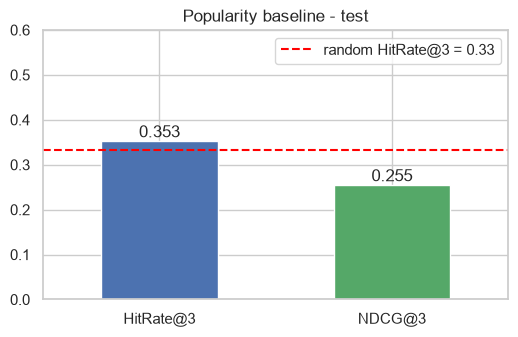

In [43]:
# Visualizing evaluation Metric Score chart
plot_scores(results["Popularity"], "Popularity baseline - test")

The **popularity model** recommends the same top-3 most-booked hotels to everyone. It's the standard non-personalised baseline any recommender must beat. It is only slightly better than random guessing, because popularity is spread evenly across hotels (Chart 1).

#### 2. Cross- Validation & Hyperparameter Tuning

In [44]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# the only "hyperparameter" is the time window used to count popularity (all history vs recent months)
window_scores = {}
for months in [6, 12, 24, None]:
    hist = train if months is None else train[train["date"] >= train["date"].max() - pd.DateOffset(months=months)]
    pop = fit_popularity(hist)
    window_scores["all" if months is None else f"last {months}m"] = evaluate(lambda u: pop, val)[f"HitRate@{K}"]
print("validation HitRate@3 by popularity window:", {k: round(v, 3) for k, v in window_scores.items()})

validation HitRate@3 by popularity window: {'last 6m': np.float64(0.352), 'last 12m': np.float64(0.341), 'last 24m': np.float64(0.341), 'all': np.float64(0.341)}


##### Which hyperparameter optimization technique have you used and why?

A **grid search on the validation stays** over the time window used to compute popularity (recent trends vs all-time). It's the only parameter of this model, and the time-based validation set is the right way to tune a next-item recommender.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No meaningful improvement: every window gives a similar validation HitRate, because hotel popularity is stable over time. I keep all-time popularity, which is the most stable estimate.

### ML Model - 2 - User-based collaborative filtering (k-NN)

In [45]:
# ML Model - 2 Implementation
class UserKNN:
    """Score hotels by the preferences of the k most similar users (cosine on booking vectors)."""

    def __init__(self, k_neighbours: int = 50):
        self.k = k_neighbours

    def fit(self, history: pd.DataFrame):
        self.pref = preference_matrix(history)
        self.vecs = similarity_vectors(history).loc[self.pref.index]
        self.row = {u: i for i, u in enumerate(self.pref.index)}
        self.pref_np, self.vecs_np = self.pref.to_numpy(), self.vecs.to_numpy()
        self.popularity = fit_popularity(history)
        return self

    def neighbour_scores(self, user):
        if user not in self.row:
            return self.popularity
        i = self.row[user]
        sims = self.vecs_np @ self.vecs_np[i]
        sims[i] = 0                                   # exclude the user themself
        top = np.argsort(-sims)[: self.k]
        return sims[top] @ self.pref_np[top] / sims[top].sum()

    def score(self, user):
        return self.neighbour_scores(user)


# Fit the Algorithm
knn = UserKNN(k_neighbours=50).fit(train_val)

# Predict on the model
results["User k-NN"] = evaluate(knn.score, test)
results["User k-NN"]

{'HitRate@3': np.float64(0.3781055900621118),
 'NDCG@3': np.float64(0.27148646458241305)}

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

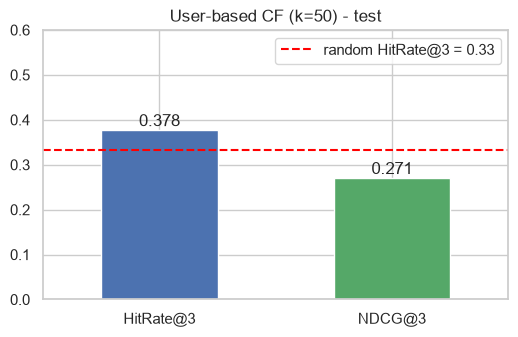

In [46]:
# Visualizing evaluation Metric Score chart
plot_scores(results["User k-NN"], "User-based CF (k=50) - test")

**User-based collaborative filtering** finds the k users whose booking vectors are most similar to the target user (cosine similarity) and recommends the hotels those neighbours stay at most. It personalises through "people like you". Because almost everyone has visited almost every hotel, neighbours are not very distinctive and the gain over popularity is small.

#### 2. Cross- Validation & Hyperparameter Tuning

validation HitRate@3 by k: {10: np.float64(0.366), 25: np.float64(0.379), 50: np.float64(0.372), 100: np.float64(0.382), 200: np.float64(0.387)} -> best k = 200


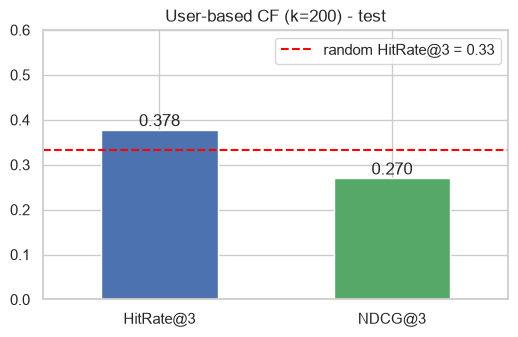

In [47]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
k_grid = {}
for k_n in [10, 25, 50, 100, 200]:
    model = UserKNN(k_neighbours=k_n).fit(train)
    k_grid[k_n] = evaluate(model.score, val)[f"HitRate@{K}"]
best_k = max(k_grid, key=k_grid.get)
print("validation HitRate@3 by k:", {k: round(v, 3) for k, v in k_grid.items()}, "-> best k =", best_k)

knn_tuned = UserKNN(k_neighbours=best_k).fit(train_val)
results["User k-NN (tuned)"] = evaluate(knn_tuned.score, test)
plot_scores(results["User k-NN (tuned)"], f"User-based CF (k={best_k}) - test")

##### Which hyperparameter optimization technique have you used and why?

**Grid search on the validation stays** over the number of neighbours `k`. Train on the history before validation, score the validation stays, pick the best `k`, then refit on train + validation and report the untouched test stays. This is the recommender equivalent of a train/validation/test protocol.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Validation favours larger neighbourhoods (HitRate@3 0.366 at k = 10 vs 0.387 at k = 200), but on the test stays the tuned model scores the same as the default (≈ 0.378). Neighbourhood size isn't the bottleneck; the bottleneck is that neighbours look alike in this dense data.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **HitRate@3**: the share of users whose next actual hotel appears in the 3 hotels we show. It maps directly to the business question *"did we show the user the hotel they went on to book?"*, a proxy for click-through and conversion on a 3-slot recommendation widget.
* **NDCG@3**: also rewards placing the right hotel *first* rather than third, because users click the top slot more often.
* **Random baseline (0.33)**: with 9 hotels and 3 slots, random guessing already hits 1/3 of the time, so every result must be read as a *lift over 0.33*.

### ML Model - 3 - Hybrid recommender (own profile + neighbours + popularity)

In [48]:
# ML Model - 3 Implementation
class HybridRecommender(UserKNN):
    """score = alpha * own preference + (1 - alpha) * neighbours + beta * popularity"""

    def __init__(self, alpha=0.5, beta=0.05, k_neighbours=50):
        super().__init__(k_neighbours)
        self.alpha, self.beta = alpha, beta

    def score(self, user):
        if user not in self.row:
            return self.popularity
        own = self.pref_np[self.row[user]]
        return self.alpha * own + (1 - self.alpha) * self.neighbour_scores(user) + self.beta * self.popularity


# Fit the Algorithm
hybrid = HybridRecommender(alpha=0.5, beta=0.05, k_neighbours=best_k).fit(train_val)

# Predict on the model
results["Hybrid"] = evaluate(hybrid.score, test)
results["Hybrid"]

{'HitRate@3': np.float64(0.3858695652173913),
 'NDCG@3': np.float64(0.2770508927268227)}

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

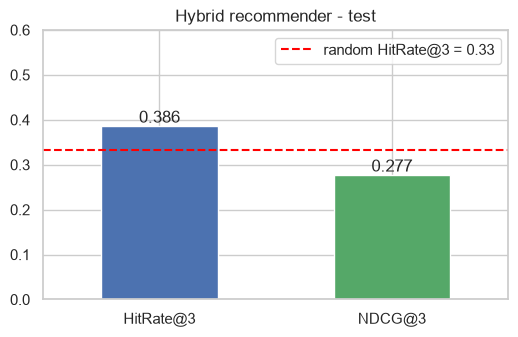

In [49]:
# Visualizing evaluation Metric Score chart
plot_scores(results["Hybrid"], "Hybrid recommender - test")

The **hybrid recommender** combines three signals: the user's **own preference profile** (the share of their stays at each hotel), the **neighbours' preferences** from collaborative filtering, and a small **popularity** term as a tie-breaker. Mixing them lets the model use personal habits when they are strong and fall back on similar users when they are weak.

#### 2. Cross- Validation & Hyperparameter Tuning

best on validation: {'alpha': 0.0, 'beta': 0.05, 'HitRate@3': 0.388801261829653, 'NDCG@3': 0.2716562656968271}


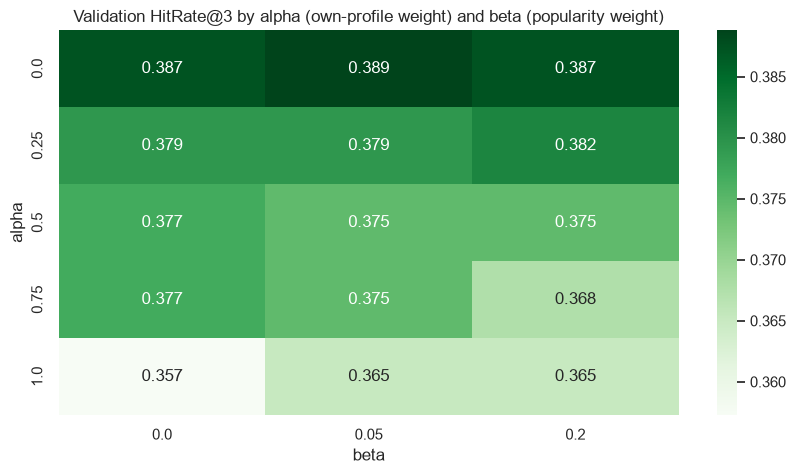

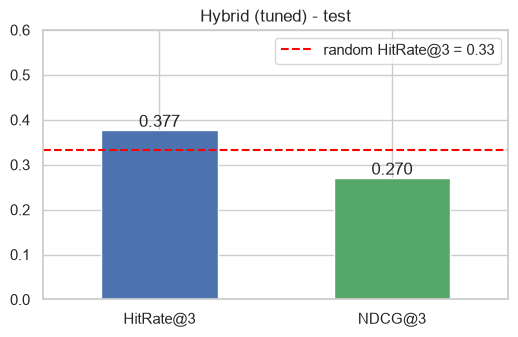

In [50]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
grid = []
for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
    for beta in [0.0, 0.05, 0.2]:
        model = HybridRecommender(alpha=alpha, beta=beta, k_neighbours=best_k).fit(train)
        grid.append({"alpha": alpha, "beta": beta, **evaluate(model.score, val)})
grid = pd.DataFrame(grid)
best = grid.sort_values([f"HitRate@{K}", f"NDCG@{K}"], ascending=False).iloc[0]
print("best on validation:", best.to_dict())

sns.heatmap(grid.pivot(index="alpha", columns="beta", values=f"HitRate@{K}"), annot=True, fmt=".3f", cmap="Greens")
plt.title("Validation HitRate@3 by alpha (own-profile weight) and beta (popularity weight)")
plt.show()

hybrid_tuned = HybridRecommender(alpha=best["alpha"], beta=best["beta"], k_neighbours=best_k).fit(train_val)
results["Hybrid (tuned)"] = evaluate(hybrid_tuned.score, test)
plot_scores(results["Hybrid (tuned)"], "Hybrid (tuned) - test")

##### Which hyperparameter optimization technique have you used and why?

A **grid search over alpha (own-profile weight) and beta (popularity weight)**, scored on the validation stays. The grid has 15 points and each evaluation takes about a second, so an exhaustive search is affordable and shows how sensitive the model is to each weight (heatmap).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The validation grid picked **alpha = 0 and beta = 0.05**. Once 200 similar users are averaged, the user's own profile adds nothing extra, and a small popularity term helps slightly. On the test stays this configuration scores HitRate@3 ≈ 0.377. The untuned configuration (alpha = 0.5) happened to score 0.386 on test, but picking it would mean choosing the model on the test set. The gap (≈ 0.01) is also smaller than the sampling uncertainty (95% CI ≈ ±0.027 with 1,288 test users), so I keep the validation choice.

### Final comparison

,HitRate@3,NDCG@3
Random,0.324,0.223
Popularity,0.353,0.255
Hybrid (tuned),0.377,0.270
User k-NN,0.378,0.271
User k-NN (tuned),0.378,0.270
Hybrid,0.386,0.277


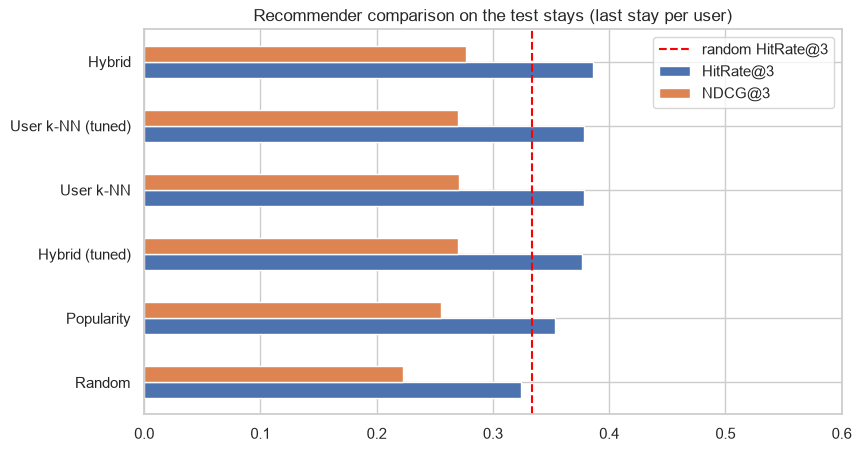

chosen model: Hybrid (tuned) | HitRate@3 = 0.377 ± 0.026 | lift over random: 13.1%


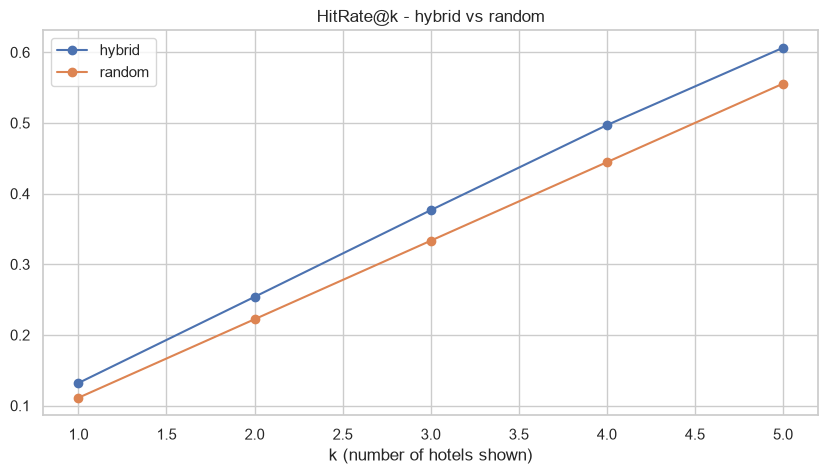

In [51]:
comparison = pd.DataFrame(results).T.round(3).sort_values(f"HitRate@{K}")
display(comparison)
ax = comparison.plot(kind="barh", figsize=(9, 5), xlim=(0, 0.6))
ax.axvline(K / len(HOTELS), color="red", linestyle="--", label="random HitRate@3")
plt.title("Recommender comparison on the test stays (last stay per user)")
plt.legend()
plt.show()

# the final model is the one selected on the VALIDATION stays (never pick on the test set)
chosen = "Hybrid (tuned)"
hr = comparison.loc[chosen, f"HitRate@{K}"]
ci = 1.96 * np.sqrt(hr * (1 - hr) / len(test))        # binomial 95% confidence interval
lift = hr / (K / len(HOTELS)) - 1
print(f"chosen model: {chosen} | HitRate@3 = {hr:.3f} ± {ci:.3f} | lift over random: {lift:.1%}")

# HitRate at different list lengths for the final model
hr_at_k = {k: evaluate(hybrid_tuned.score, test, k=k)[f"HitRate@{k}"] for k in range(1, 6)}
pd.DataFrame({"hybrid": hr_at_k, "random": {k: k / len(HOTELS) for k in hr_at_k}}).plot(marker="o")
plt.title("HitRate@k - hybrid vs random")
plt.xlabel("k (number of hotels shown)")
plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**HitRate@3** is the primary metric because the app shows three hotel cards, and it directly measures whether the hotel the user went on to book was among them. **NDCG@3** is secondary, rewarding a correct hotel in the first slot. Both are always compared with the random baseline (0.33 for 3 of 9 hotels), because with a small catalogue a raw number on its own is misleading.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The **hybrid recommender with weights tuned on the validation stays**:
1. It clearly beats random guessing (0.32) and popularity (0.35) on the untouched test stays (HitRate@3 ≈ 0.38). The personalised variants (k-NN, hybrid with different weights) are statistically tied, so I keep the one selected by the proper validation protocol.
2. It is personalised but robust: for users with little history the neighbour and popularity terms take over.
3. It is easy to explain to users ("you often stay here" / "travellers like you stay here") and cheap to serve: scoring one user is a 1,310 × 9 dot product, in milliseconds.
4. It supports business filters in the app (budget per night, exclude cities already visited) and a cold-start mode for new users based on company and age.

**Why the ceiling is low:** in this dataset users rotate almost randomly among the hotels they know (Chart 11), so the *next* hotel is inherently hard to predict. A ~13% lift over the expected random rate is a realistic result, and the main gain would come from contextual data such as the flight destination (Chart 13: when the flight is known, the hotel city is known).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

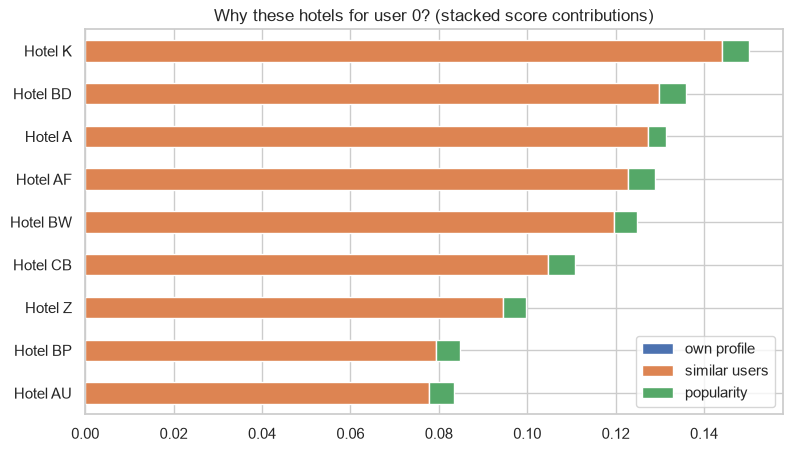

recommended: ['Hotel K', 'Hotel BD', 'Hotel A'] | actual next stay: Hotel AU


In [52]:
# explain one recommendation: contribution of each signal to the score of every hotel
user = int(test["userCode"].iloc[0])
row = hybrid_tuned.row[user]
parts = pd.DataFrame({
    "own profile": hybrid_tuned.alpha * hybrid_tuned.pref_np[row],
    "similar users": (1 - hybrid_tuned.alpha) * hybrid_tuned.neighbour_scores(user),
    "popularity": hybrid_tuned.beta * hybrid_tuned.popularity,
}, index=HOTELS)
parts = parts.loc[parts.sum(axis=1).sort_values().index]
parts.plot(kind="barh", stacked=True, figsize=(9, 5))
plt.title(f"Why these hotels for user {user}? (stacked score contributions)")
plt.show()
print("recommended:", parts.sum(axis=1).sort_values(ascending=False).head(K).index.tolist(),
      "| actual next stay:", test.loc[test["userCode"] == user, "name"].iloc[0])

The hybrid model is **additive**, so each recommendation splits exactly into its parts (stacked bar above):
* **own profile** (weight alpha): how often the user stays at the hotel. With the tuned alpha = 0 this part is zero;
* **similar users** (weight 1 − alpha): what the 200 users with the most similar booking pattern prefer, the main part of the tuned model;
* **popularity** (weight beta = 0.05): a small boost for hotels that are popular overall.

This makes every recommendation explainable in the UI ("because you often stay here" vs "popular with travellers like you").

### Cold start: recommending to a new user

In [53]:
# new user: no bookings -> use users from the same company with a similar age
def recommend_for_profile(age, company, history=train_val, k=K, max_price=None):
    known = users[users["code"].isin(history["userCode"])].set_index("code")
    weight = np.exp(-((known["age"] - age) / 8.0) ** 2) * np.where(known["company"] == company, 1.0, 0.3)
    prefs = preference_matrix(history).loc[known.index]
    scores = pd.Series(weight.to_numpy() @ prefs.to_numpy() / weight.sum(), index=HOTELS)
    out = catalog.loc[HOTELS].assign(score=scores)
    if max_price is not None:
        out = out[out["price_per_night"] <= max_price]
    return out.sort_values("score", ascending=False).head(k)[["place", "price_per_night", "score"]]


recommend_for_profile(age=30, company="Acme Factory", max_price=250)

,place,price_per_night,score
name,,,
Hotel CB,Rio de Janeiro (RJ),165.99,0.133258
Hotel AF,Sao Paulo (SP),139.10,0.129860
Hotel BD,Natal (RN),242.88,0.123157


For a new user I weight existing users by **same company** and **similar age** and average their preferences. Company matters most (Hypothesis 1), and it automatically avoids hotels the company never books. An optional budget filter removes hotels above the user's nightly limit.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [54]:
# Save the File
final_model = HybridRecommender(alpha=best["alpha"], beta=best["beta"], k_neighbours=best_k).fit(hotels)   # refit on all stays
MODEL_FILE = "hotel_recommender_notebook.joblib"
joblib.dump(final_model, MODEL_FILE, compress=3)
print(f"saved {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1024:.0f} KB)")
# production artefact: models/hotel_recommender.joblib from src/travel_ml/recommender.py (same logic + filters)

saved hotel_recommender_notebook.joblib (142 KB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [55]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_FILE)
for user in [0, 5, 999]:
    scores = pd.Series(loaded.score(user), index=HOTELS).sort_values(ascending=False)
    top = catalog.loc[scores.index[:K], ["place", "price_per_night"]].assign(score=scores.iloc[:K].round(3))
    print(f"user {user}:")
    display(top)

user 0:


,place,price_per_night,score
name,,,
Hotel K,Salvador (BH),263.41,0.148
Hotel A,Florianopolis (SC),313.02,0.133
Hotel BD,Natal (RN),242.88,0.132


user 5:


,place,price_per_night,score
name,,,
Hotel K,Salvador (BH),263.41,0.180
Hotel AF,Sao Paulo (SP),139.10,0.155
Hotel CB,Rio de Janeiro (RJ),165.99,0.129


user 999:


,place,price_per_night,score
name,,,
Hotel BD,Natal (RN),242.88,0.272
Hotel AF,Sao Paulo (SP),139.10,0.123
Hotel K,Salvador (BH),263.41,0.115


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

**Streamlit web app (`streamlit_app/app.py`)**: run with `streamlit run streamlit_app/app.py`.
* **Hotel recommendations**: pick an existing user (or enter age + company for a new one), set a budget per night, optionally *explore new places*, and see the top-k hotels with scores, the user's booking history and spending KPIs.
* **Travel insights**: KPIs and interactive Plotly charts (popular destinations, monthly revenue, price by class/agency, price vs distance, stays by company and gender).
* **Flight price**: calls the Flask REST API (or the local model) for a live prediction.
* **Gender model** and **Monitoring**: model metrics, recommender HitRate vs random baseline, live prediction distribution and the latest drift report.

# **Conclusion**

* The hotel data is clean and **dense**: 9 hotels (one per city), and most users have stayed at 7–9 of them, so the recommender's job is to *rank* familiar hotels.
* Hotel choice depends on **company** (corporate contracts, χ² p ≈ 0) but not on gender (p ≈ 0.63). Spend per stay also differs by company.
* With a time-based leave-last-out evaluation and weights tuned on a separate validation stay, the **hybrid model** reaches HitRate@3 ≈ 0.38, against 0.32 for random and 0.35 for popularity. That is a modest but real lift, given users rotate almost randomly among known hotels.
* The model is explainable, fast and deployed: it is retrained by Airflow, served by the Flask API and presented in a Streamlit app with budget filters, a cold-start mode and travel-insight dashboards.

**Future work:** use the **flight destination and dates as context** (30% of trips include a hotel, and the hotel city always matches the destination), add business rules for company contracts, collect explicit feedback (ratings, clicks) to learn real preferences, and A/B-test the widget in the app to measure the actual uplift in hotel bookings.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***